# A04 — Plate model comparison: paths of continents through time


**Cluster A: Getting started + core workflows.**
**Where do two plate-reconstruction models disagree, and by how much?**

## What this notebook produces

Two figures: (1) a **Mercator map** of India's reconstructed track through the Cenozoic, with the Zahirovic 2022 path in red and the Merdith 2021 path in blue overlaid on the same projection; and (2) a **chart** of inter-model great-circle disagreement (in km) as a function of reconstruction age, shown twice: in the models' own absolute frames (anchor plate 0) and for India relative to Eurasia (plate 301), which removes the reference-frame difference between the two models.

**Audience**: postgraduate.  
**Difficulty**: ★★☆.


## Learning objectives

- Reconstruct a common point (on India) through time under two plate models (Zahirovic 2022 and Merdith 2021).
- Compute the great-circle distance between the two predicted positions at each age.
- Separate the effect of the models' absolute reference frames from the effect of their relative plate motions by repeating the comparison for India relative to Eurasia.


## Prerequisites and runtime

- **Plate models compared**: Zahirovic 2022 (default) and Merdith 2021.
- **Time**: 0–120 Ma (map stamped at 80 Ma).
- **Python**: `gplately`, `pygmt`, `pygplates`, `numpy`.
- **Runtime**: \~1 minute.


In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports + load both models
import numpy as np, pandas as pd
import gplately, pygmt
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from IPython.display import display, HTML

# Suite-wide tutorial style: bigger panel titles, 1cm gap between figures.
pygmt.config(FONT_TITLE="18p", FONT_LABEL="18p",
             FONT_ANNOT_PRIMARY="14p")

pmm = LocalFirstPMM()
MODELS = ["Zahirovic2022", "Merdith2021"]
recons = {}
for name in MODELS:
    m = pmm.get_model(name, data_dir="./gplately_data")
    recons[name] = gplately.PlateReconstruction(
        rotation_model=m.get_rotation_model(),
        topology_features=m.get_topologies(),
        static_polygons=m.get_static_polygons(),
    )
# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0.post19+git.2cce7bb3  pygmt v0.19.0  pygplates 1.0.0


## Configuration

User-tunable choices for this notebook. Edit the values below to change the model, snapshot time, region, or anchor plate without hunting through downstream code.


In [2]:
# === USER CONFIGURATION =====================================================
MODEL_A              = "Zahirovic2022"
MODEL_B              = "Merdith2021"
RECONSTRUCTION_TIME  = 80.0          # Ma — common snapshot for both models
ANCHOR_PLATE_ID      = 0
REGION               = [40, 110, -45, 30]   # India / Tethys focus
MODEL_NAME           = f"{MODEL_A}/{MODEL_B}"   # combined label for the stamp
# ============================================================================


In [3]:
# Cell 2 — reconstruct India through time in both models
INDIA_PID = 501
times = list(range(0, 121, 10))
tracks = {}
for name, recon in recons.items():
    pt = gplately.Points(plate_reconstruction=recon,
                         lons=[77.0], lats=[20.0], plate_id=INDIA_PID)
    track = []
    for t in times:
        plon, plat = pt.reconstruct(time=t, return_array=True)
        track.append((t, plat[0], plon[0]))
    tracks[name] = np.array(track)
    print(f"{name}: {len(track)} positions")

# The same India track relative to Eurasia (plate 301). Anchoring on a plate
# of the same model removes the dependence on the absolute reference frame,
# so any remaining difference comes from the relative plate motions alone.
EURASIA_PID = 301
tracks_eur = {}
for name, recon in recons.items():
    pt = gplately.Points(plate_reconstruction=recon,
                         lons=[77.0], lats=[20.0], plate_id=INDIA_PID)
    track = []
    for t in times:
        plon, plat = pt.reconstruct(time=t, anchor_plate_id=EURASIA_PID, return_array=True)
        track.append((t, plat[0], plon[0]))
    tracks_eur[name] = np.array(track)

Zahirovic2022: 13 positions
Merdith2021: 13 positions


### What the two figures show

**Figure 1 — the two tracks.** Compare where the red and blue tracks pinch together (the models agree) and where they spread apart (the models disagree). Both tracks are drawn with anchor plate 0, but plate ID 0 does not stand for the same reference frame in the two models: in Merdith 2021 it is a paleomagnetic frame, whereas in Zahirovic 2022 it is an optimised mantle frame (see **F02** and **F03** for what such frames mean). The separation between the tracks therefore combines two things: the difference between the two absolute frames, and the difference in how each model moves India relative to the rest of its plate circuit.

**Figure 2 — the disagreement chart.** The black curve converts the separation of the two tracks in Figure 1 into one number per age. The purple curve repeats the comparison for India relative to Eurasia (plate 301), which does not depend on the absolute frame and so isolates the disagreement in relative plate motion. Where the black curve lies well above the purple one, most of the disagreement is the reference frame, not the India–Eurasia plate circuit. A disagreement of ≲ 200 km is well within the uncertainty of both models; ≳ 1000 km is large enough to matter for any quantitative claim.


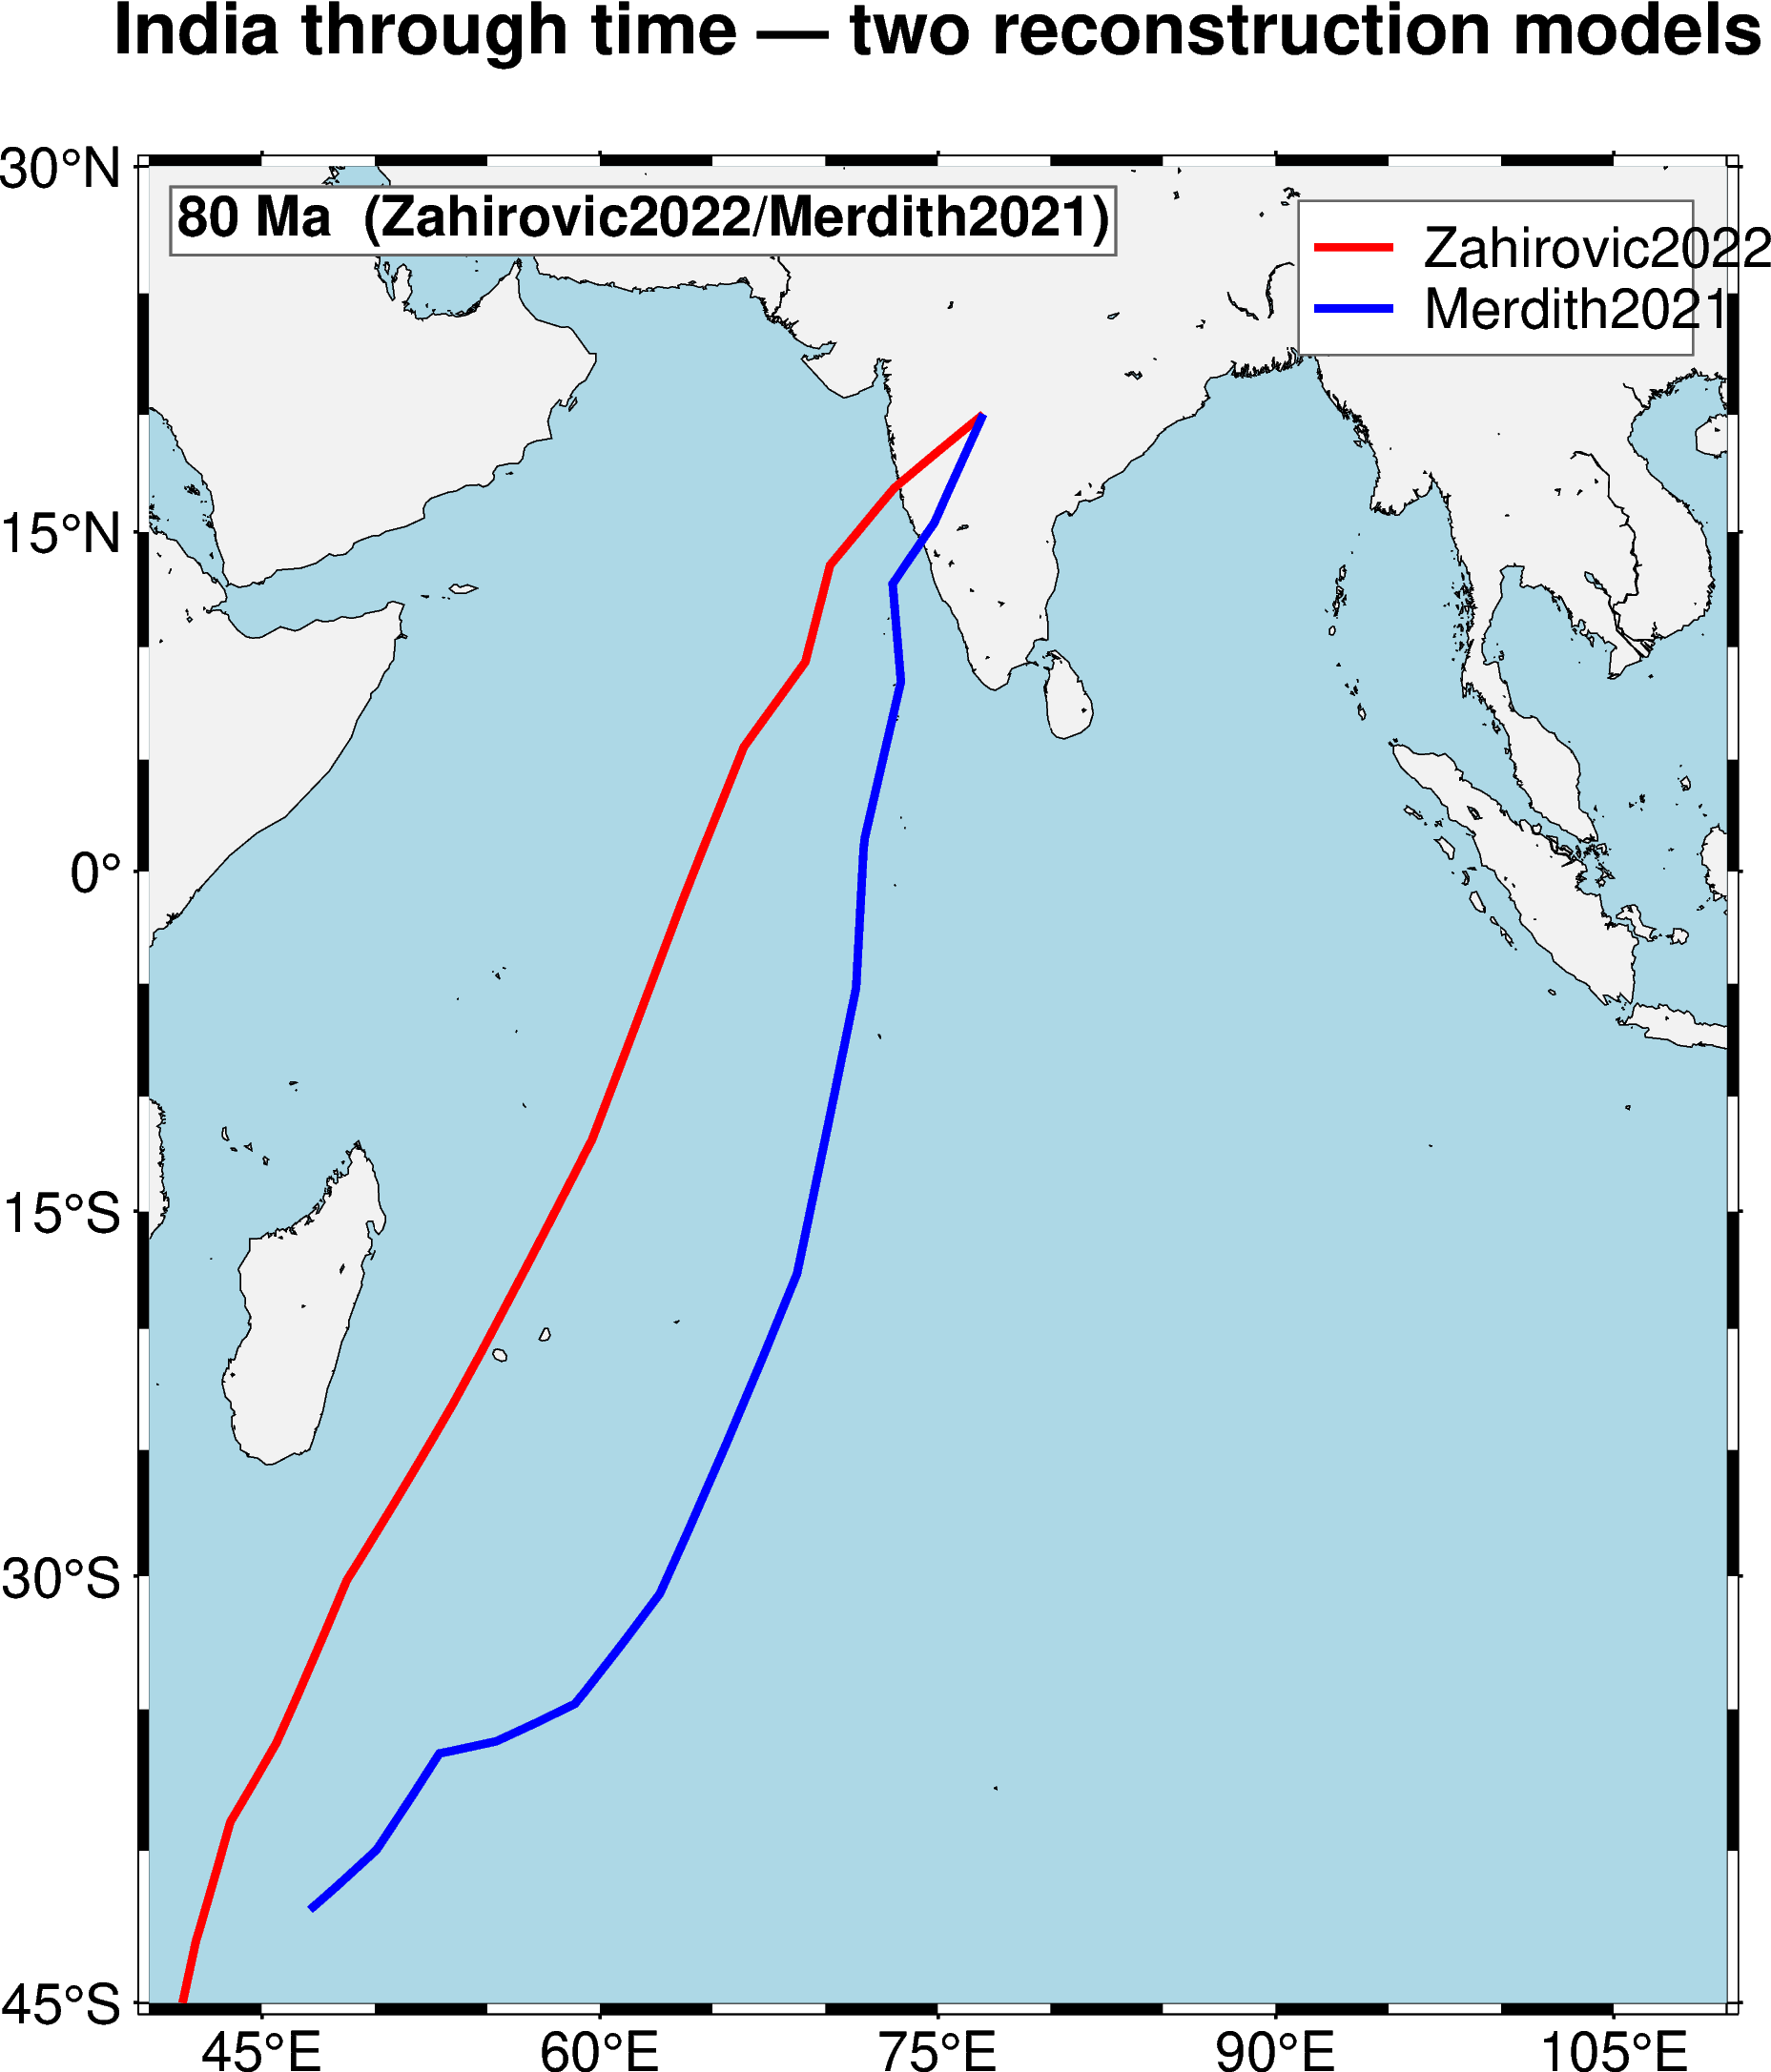

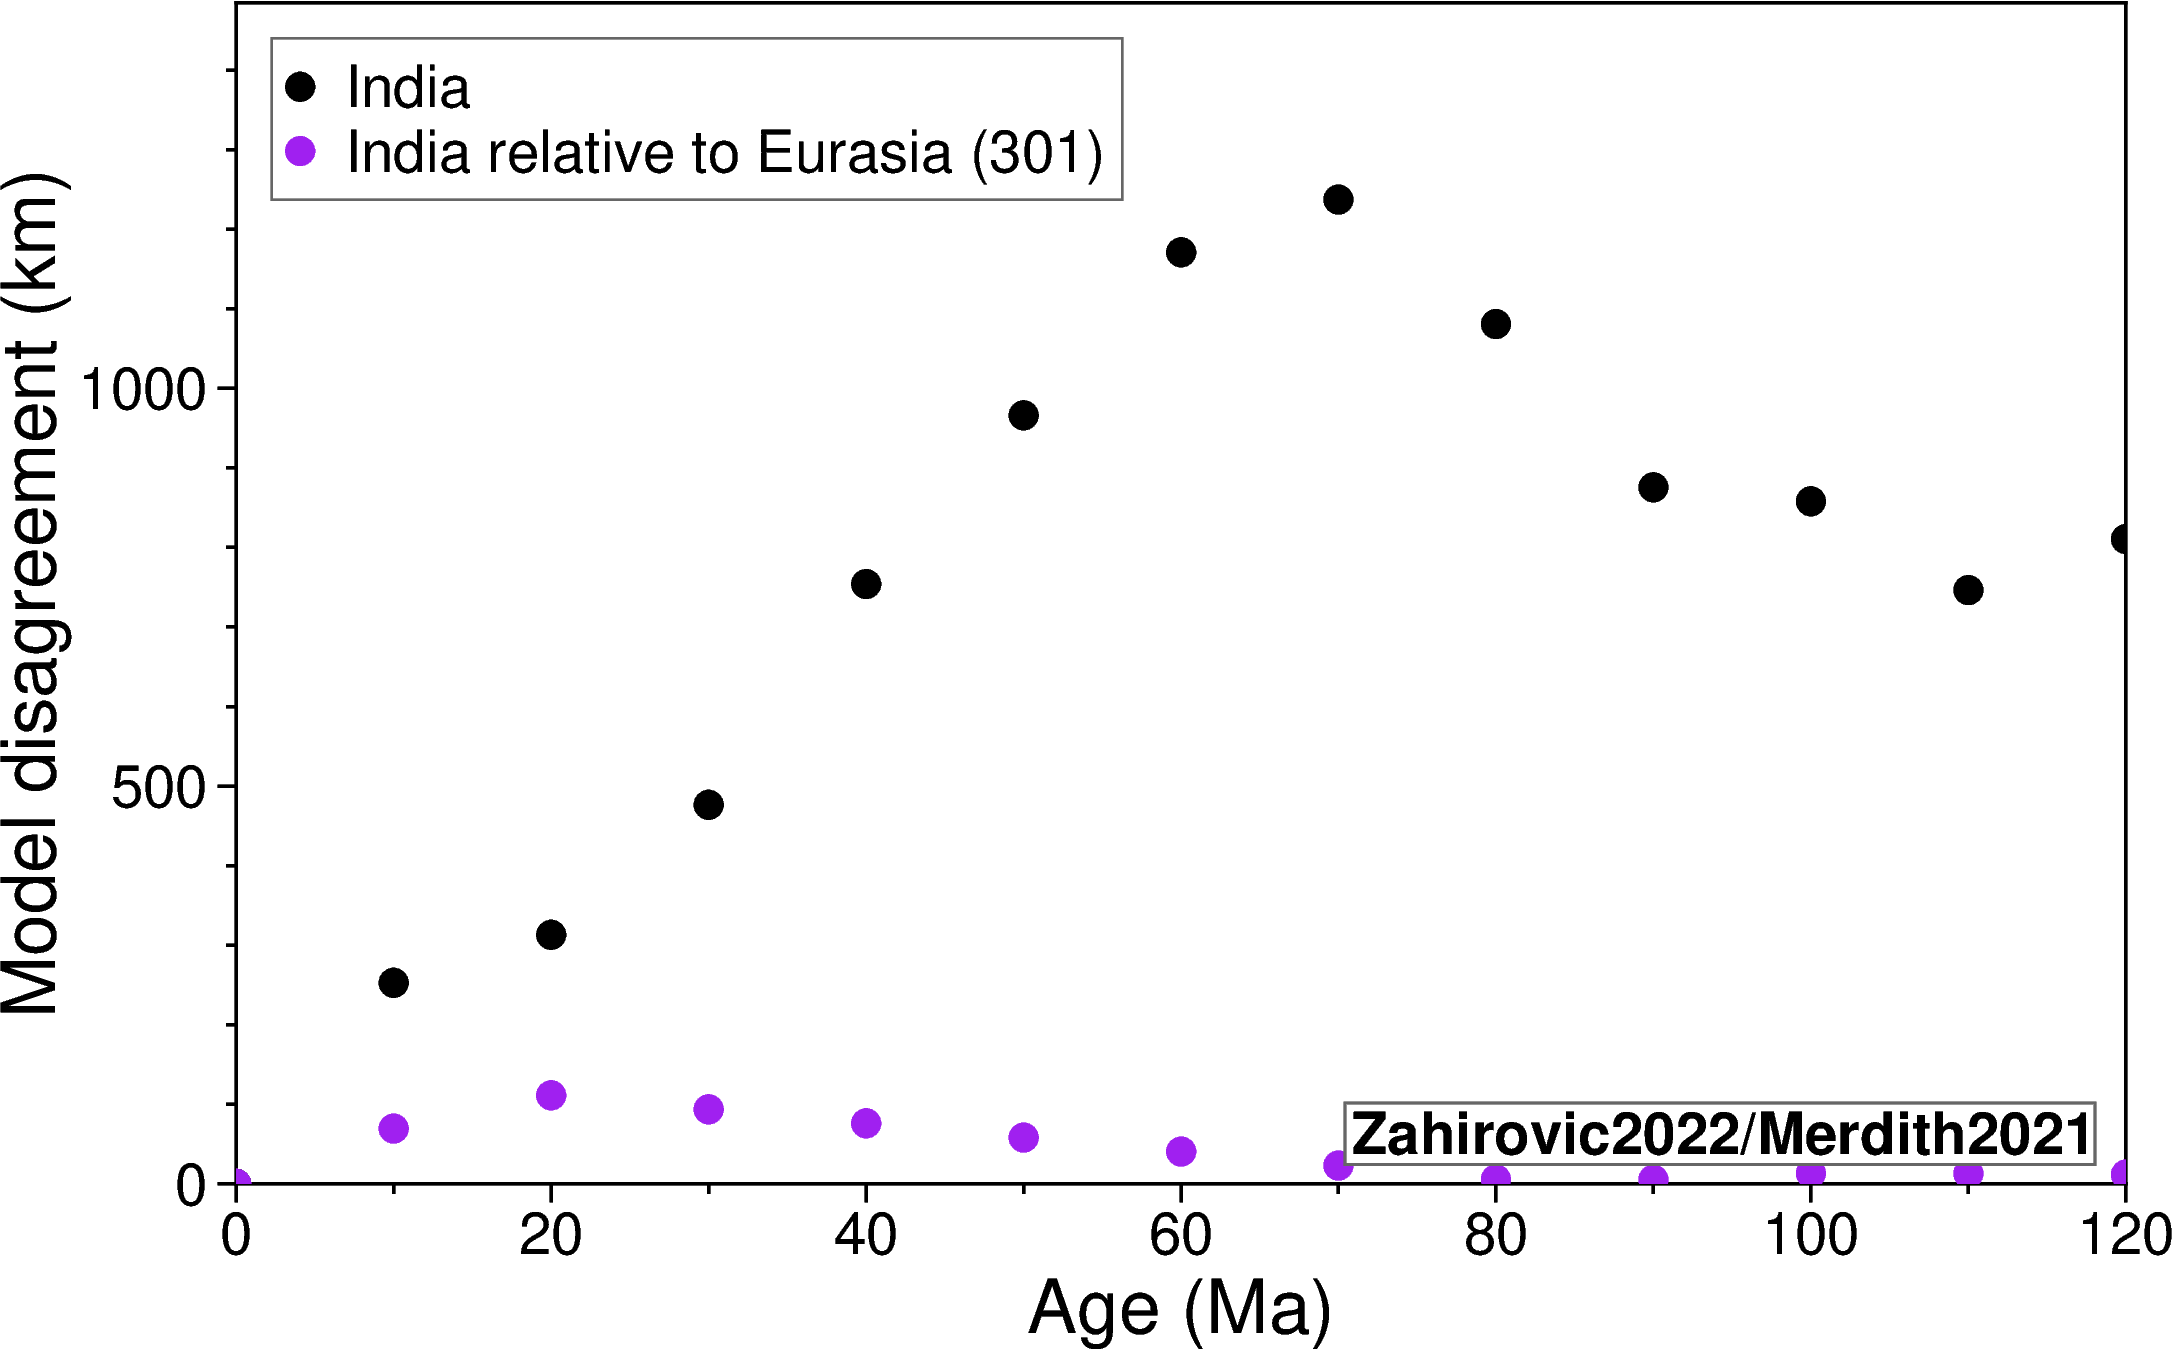

In [4]:
# Cell 3 — figure 1 of 2: India migration paths from the two models
fig = pygmt.Figure()
fig.basemap(region=[40, 110, -45, 30], projection="M14c",
            frame=["af", '+tIndia through time — two reconstruction models'])
fig.coast(land="gray95", water="lightblue", shorelines=True)
cols = ["red", "blue"]
for (name, tr), c in zip(tracks.items(), cols):
    fig.plot(x=tr[:,2], y=tr[:,1], pen=f"2p,{c}", label=name)
fig.legend(position="JTR+jTR+o0.3c/0.3c+w3.5c", box="+gwhite+p0.5p,gray40")
fig.text(text=f"{RECONSTRUCTION_TIME:.0f} Ma  ({MODEL_NAME})",
         position="TL", offset="0.25c/-0.25c", justify="TL",
         font="14p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")
fig.show(width=650)
display(HTML('<div style="height:1cm"></div>'))
# Figure 2 of 2: per-time model disagreement, in km of great-circle distance
def _gc_km(lat1, lon1, lat2, lon2):
    dl = np.deg2rad(lon2 - lon1)
    a = np.sin(np.deg2rad(lat2 - lat1) / 2) ** 2 + \
        np.cos(np.deg2rad(lat1)) * np.cos(np.deg2rad(lat2)) * np.sin(dl / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

def _disagreement(trk):
    a, b = trk[MODELS[0]], trk[MODELS[1]]
    return [_gc_km(a[i, 1], a[i, 2], b[i, 1], b[i, 2]) for i in range(len(times))]

diff_km     = _disagreement(tracks)       # anchor plate 0: frames + relative motion
diff_km_eur = _disagreement(tracks_eur)   # India relative to Eurasia: relative motion only

fig = pygmt.Figure()
fig.basemap(region=[0, 120, 0, max(max(diff_km), max(diff_km_eur)) * 1.2],
            projection="X16c/10c",
            frame=["xaf+lAge (Ma)",
                   "yaf+lModel disagreement (km)",
                   "WSrt"])
fig.plot(x=times, y=diff_km, pen="1.5p,black", style="c0.2c", fill="black",
         label="India, anchor plate 0")
fig.plot(x=times, y=diff_km_eur, pen="1.5p,purple", style="c0.2c", fill="purple",
         label="India relative to Eurasia (301)")
fig.legend(position="JTL+jTL+o0.3c", box="+gwhite+p0.5p,gray40")
fig.text(text=f"{MODEL_NAME}",
         position="BR", offset="-0.25c/0.25c", justify="BR",
         font="14p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")
fig.show(width=650)
display(HTML('<div style="height:1cm"></div>'))


## Extend this

- **Try a different plate.** Re-run the cells with another `plate_id` (e.g. Africa = 701, the Pacific Plate = 901) to see the per-plate disagreement budget between Zahirovic 2022 and Merdith 2021.
- **Bring in a third model.** Add Cao 2024 or Müller 2022 as a third track and chart pairwise disagreements.
- **Cumulative disagreement.** Plot the time-integrated path-length difference instead of the per-time great-circle disagreement.

## References

- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geosci. Data J.* 11, 3-10. https://doi.org/10.1002/gdj3.185
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J., Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochem. Geophys. Geosys.* 20, 5556-5564. https://doi.org/10.1029/2019GC008515

- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146
